## Chia train/val/test theo bệnh nhân
- Đầu vào: `data/windows_thr88/*.npz` và `data/windows_thr88_summary.parquet`.
- Đầu ra: `data/splits_thr88.parquet` (bệnh nhân nào thuộc tập nào) và `data/dataset_thr88/{train,val,test}.npz`.
- Mỗi file gồm: `X` (n, 60, 6), `y`, `start`, `pid`, `rec`, `is_1hz`.
- Chia theo **bệnh nhân**, không chia theo cửa sổ, vì các cửa sổ cùng bệnh nhân rất giống nhau.
- Cách chia được lưu và dùng lại. Muốn chia lại: xóa `data/splits_thr88.parquet` và thư mục `data/dataset_thr88`.
- Quy tắc dùng: val để chọn ngưỡng và dừng sớm; test chỉ mở **một lần** ở cuối.

In [1]:
import os, numpy as np, pandas as pd

WIN_DIR = "data/windows_thr88"
SUMMARY = f"{WIN_DIR}_summary.parquet"
SPLIT_PATH, OUT_DIR = "data/splits_thr88.parquet", "data/dataset_thr88"
FRAC = {"train": .70, "val": .15, "test": .15}
os.makedirs(OUT_DIR, exist_ok=True)

s = pd.read_parquet(SUMMARY).query("n_win > 0")
pt = s.groupby("patient_id").agg(n_win=("n_win", "sum"), n_pos=("n_pos", "sum"),
                                 has_1hz=("loai_fs", lambda x: (x == "1 Hz").any()))
pt["strata"] = (pt["n_pos"] > 0).astype(int).astype(str) + "_" + pt["has_1hz"].map({True: "1Hz", False: "1min"})

def assign(seed):
    rng, out = np.random.default_rng(seed), pd.Series(index=pt.index, dtype=object)
    for _, idx in pt.groupby("strata").groups.items():
        idx = rng.permutation(np.array(idx)); n = len(idx)
        a, b = int(round(FRAC["train"] * n)), int(round((FRAC["train"] + FRAC["val"]) * n))
        out[idx[:a]], out[idx[a:b]], out[idx[b:]] = "train", "val", "test"
    return out

def score(sp):   # độ lệch của tỷ lệ dương và tỷ trọng cửa sổ so với mục tiêu
    g = pt.groupby(sp)[["n_win", "n_pos"]].sum(); rate = g["n_pos"] / g["n_win"]
    base = pt["n_pos"].sum() / pt["n_win"].sum(); share = g["n_win"] / g["n_win"].sum()
    return (rate / base - 1).abs().max() + max(abs(share[k] - v) / v for k, v in FRAC.items())

if os.path.exists(SPLIT_PATH):
    sp = pd.read_parquet(SPLIT_PATH).set_index("patient_id")["split"]
    print(f"Dùng lại cách chia đã lưu: {SPLIT_PATH} ({len(sp)} bệnh nhân)")
else:
    best = min(range(300), key=lambda sd: score(assign(sd)))
    sp = assign(best)
    sp.rename("split").reset_index().to_parquet(SPLIT_PATH, index=False)
    print(f"Chọn seed {best} (độ lệch {score(sp):.3f}) và lưu {SPLIT_PATH}")

s["split"] = s["patient_id"].map(sp)
for k in FRAC:
    f = f"{OUT_DIR}/{k}.npz"
    if os.path.exists(f):
        print(f"Bỏ qua {k} (đã có {f})"); continue
    parts = [(np.load(f"{WIN_DIR}/{r.name}.npz"), r.patient_id, r.name, r.loai_fs == "1 Hz")
             for r in s[s["split"] == k].itertuples()]
    X = np.concatenate([z["X"] for z, *_ in parts]); y = np.concatenate([z["y"] for z, *_ in parts])
    np.savez(f"{f}.tmp.npz", X=X, y=y,
             start=np.concatenate([z["start"] for z, *_ in parts]),
             pid=np.concatenate([np.full(len(z["y"]), p) for z, p, *_ in parts]),
             rec=np.concatenate([np.full(len(z["y"]), n) for z, _, n, _ in parts]),
             is_1hz=np.concatenate([np.full(len(z["y"]), h) for z, *_, h in parts]))
    os.replace(f"{f}.tmp.npz", f)
    print(f"Đã lưu {k}: {X.shape}, dương {int(y.sum())}")

Chọn seed 130 (độ lệch 0.057) và lưu data/splits_thr88.parquet
Đã lưu train: (340195, 60, 4), dương 4205
Đã lưu val: (70513, 60, 4), dương 868
Đã lưu test: (71600, 60, 4), dương 917


Không có bệnh nhân nào xuất hiện ở hơn một tập.


,patients,pat_pos,windows,pos,rate,pct_1hz,rate_1hz,rate_1min
train,559,252,340195,4205,0.012361,0.70514,0.011935,0.013379
val,121,54,70513,868,0.01231,0.585183,0.012699,0.011761
test,119,54,71600,917,0.012807,0.705545,0.013599,0.010909


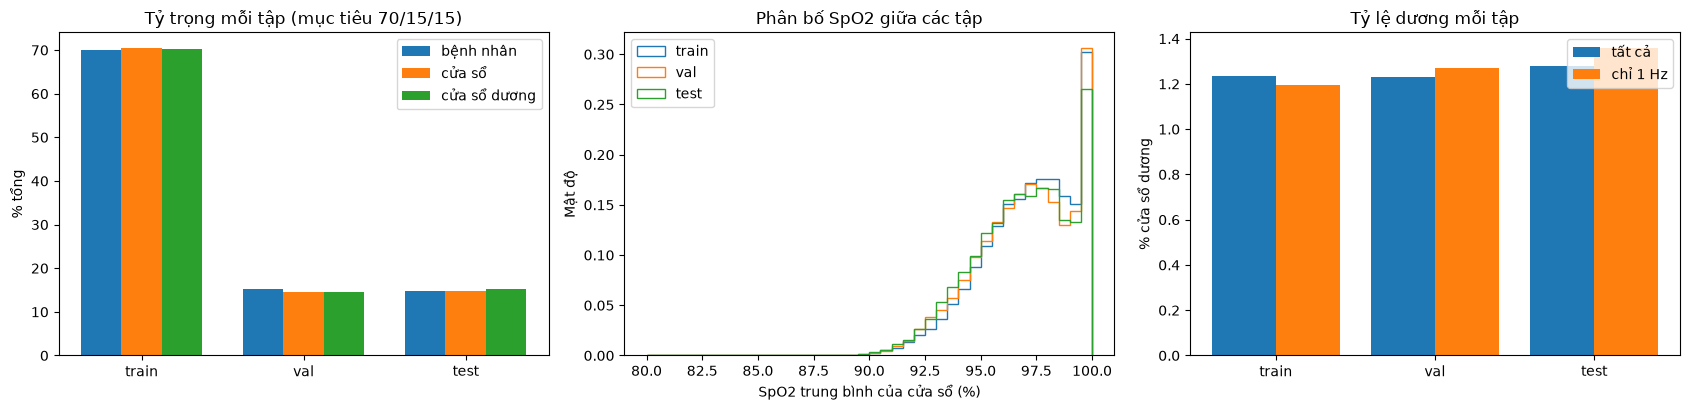

In [2]:
import matplotlib.pyplot as plt
info, mean_spo2 = {}, {}
for k in FRAC:
    z = np.load(f"{OUT_DIR}/{k}.npz"); y, pid, h = z["y"], z["pid"], z["is_1hz"]
    mean_spo2[k] = np.nanmean(z["X"][:, :, 0], axis=1)
    info[k] = dict(pid=set(pid), patients=len(set(pid)), pat_pos=len(set(pid[y == 1])), windows=len(y),
                   pos=int(y.sum()), rate=y.mean(), pct_1hz=h.mean(),
                   rate_1hz=y[h].mean() if h.any() else np.nan, rate_1min=y[~h].mean() if (~h).any() else np.nan)
assert not (info["train"]["pid"] & info["val"]["pid"] or info["train"]["pid"] & info["test"]["pid"]
            or info["val"]["pid"] & info["test"]["pid"]), "Có bệnh nhân nằm ở nhiều tập!"
print("Không có bệnh nhân nào xuất hiện ở hơn một tập.")
tab = pd.DataFrame(info).T.drop(columns="pid")
display(tab.astype({"patients": int, "pat_pos": int, "windows": int, "pos": int}).round(4))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2)); sp_ = list(FRAC); w = .25
for j, (col, lab) in enumerate((("patients", "bệnh nhân"), ("windows", "cửa sổ"), ("pos", "cửa sổ dương"))):
    ax[0].bar(np.arange(3) + (j - 1) * w, [tab.loc[k, col] / tab[col].sum() * 100 for k in sp_], w, label=lab)
ax[0].set_xticks(range(3)); ax[0].set_xticklabels(sp_); ax[0].set_ylabel("% tổng"); ax[0].legend()
ax[0].set_title("Tỷ trọng mỗi tập (mục tiêu 70/15/15)")
for k in sp_: ax[1].hist(mean_spo2[k], bins=np.arange(80, 100.5, .5), density=True, histtype="step", label=k)
ax[1].set_xlabel("SpO2 trung bình của cửa sổ (%)"); ax[1].set_ylabel("Mật độ"); ax[1].set_title("Phân bố SpO2 giữa các tập"); ax[1].legend()
ax[2].bar(np.arange(3) - .2, [tab.loc[k, "rate"] * 100 for k in sp_], .4, label="tất cả")
ax[2].bar(np.arange(3) + .2, [tab.loc[k, "rate_1hz"] * 100 for k in sp_], .4, label="chỉ 1 Hz")
ax[2].set_xticks(range(3)); ax[2].set_xticklabels(sp_); ax[2].set_ylabel("% cửa sổ dương"); ax[2].set_title("Tỷ lệ dương mỗi tập"); ax[2].legend()
plt.tight_layout(); plt.show()